In [14]:
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt

# Pfad zur CSV-Datei
file_path =     '../logs/ransomware_log.csv'


# CSV-Datei einlesen
try:
    df = pd.read_csv(file_path)
    print(f"Datei '{file_path}' erfolgreich eingelesen.")
    display(df)
except FileNotFoundError:
    print(f"Fehler: Die Datei '{file_path}' wurde nicht gefunden. Bitte stellen Sie sicher, dass der Pfad korrekt ist und die Datei existiert.")
except Exception as e:
    print(f"Ein Fehler ist beim Einlesen der Datei aufgetreten: {e}")

Datei '../logs/ransomware_log.csv' erfolgreich eingelesen.


,timestamp,uid,tgid,pid,op,bytes
0,2026-02-20T00:07:44.831764581Z,0,1805,1805,OPEN,0
1,2026-02-20T00:07:44.831791021Z,0,1805,1805,READ,0
2,2026-02-20T00:07:44.831812031Z,0,1805,1805,READ,0
3,2026-02-20T00:07:44.832560199Z,0,1803,1803,OPEN,0
4,2026-02-20T00:07:44.832574109Z,0,1803,1803,READ,0
...,...,...,...,...,...,...
343989,2026-02-20T00:24:05.715359313Z,0,1808,1808,WRITE,0
343990,2026-02-20T00:24:05.753775702Z,0,1804,1804,OPEN,0
343991,2026-02-20T00:24:05.753800801Z,0,1804,1804,READ,0
343992,2026-02-20T00:24:05.754756206Z,0,1804,1804,OPEN,0


In [15]:
# Überprüfen der Spalten, um 'read' und 'write' zu finden.
# Oftmals sind diese Informationen in einer 'operation' oder 'event' Spalte enthalten.
# Ich werde davon ausgehen, dass es eine Spalte gibt, die solche Operationen beschreibt.
# Bitte passen Sie 'operation_column' an, falls der Spaltenname abweicht.

operation_column = 'op' # Annahme: Spaltenname ist 'operation'


if operation_column in df.columns:
    # 'read' und 'write' Operationen zählen (Groß-/Kleinschreibung ignorieren)
    read_count = df[operation_column].astype(str).str.contains('read', case=False, na=False).sum()
    write_count = df[operation_column].astype(str).str.contains('write', case=False, na=False).sum()

    print(f"Anzahl der 'read'-Operationen: {read_count}")
    print(f"Anzahl der 'write'-Operationen: {write_count}")

    # Verhältnis berechnen
    if write_count > 0:
        ratio = read_count / write_count
        print(f"Verhältnis 'read' zu 'write': {ratio:.2f}")
    else:
        print("Es gab keine 'write'-Operationen, daher kann kein Verhältnis berechnet werden.")
else:
    print(f"Fehler: Die Spalte '{operation_column}' wurde im DataFrame nicht gefunden. Bitte überprüfen Sie den Spaltennamen und passen Sie den Code entsprechend an.")

Anzahl der 'read'-Operationen: 165187
Anzahl der 'write'-Operationen: 164246
Verhältnis 'read' zu 'write': 1.01



--- Analyse für Intervall: 250ms ---


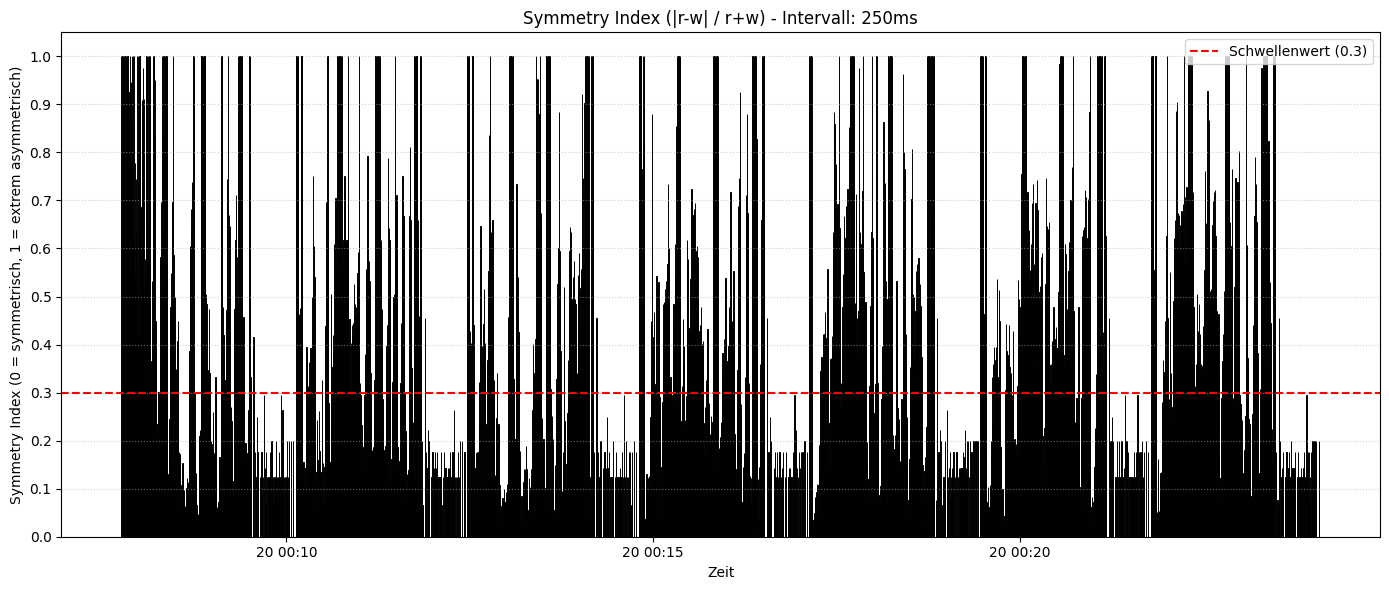


--- Analyse für Intervall: 500ms ---


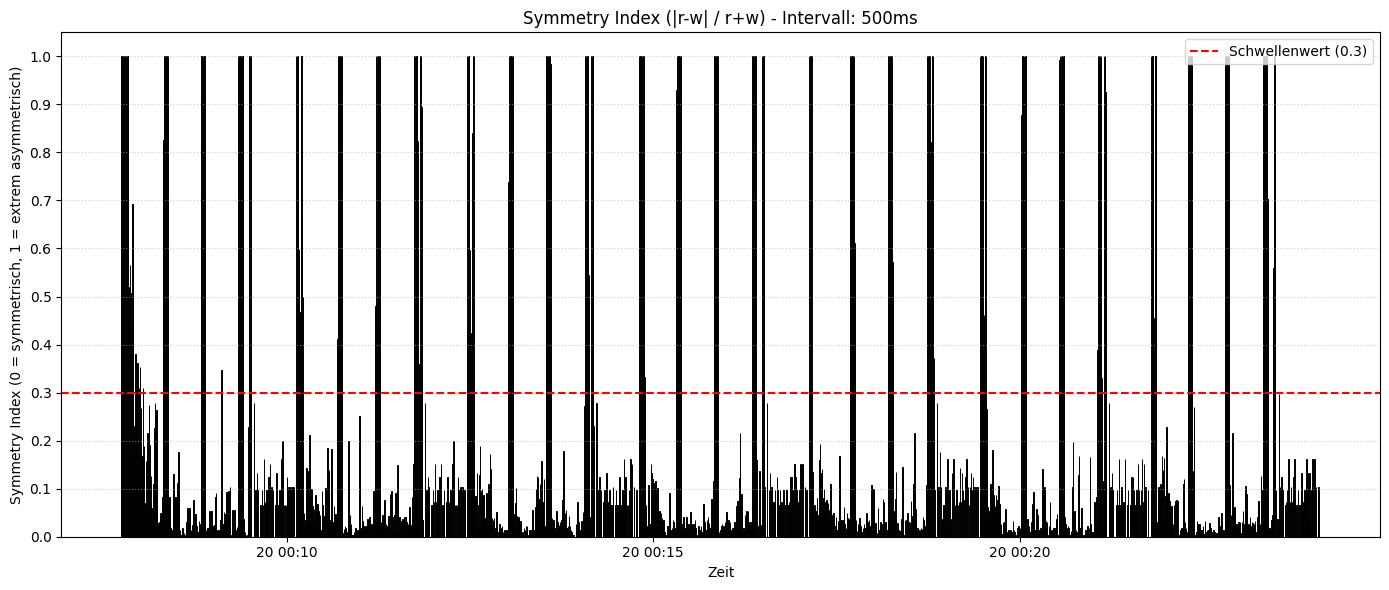


--- Analyse für Intervall: 1s ---


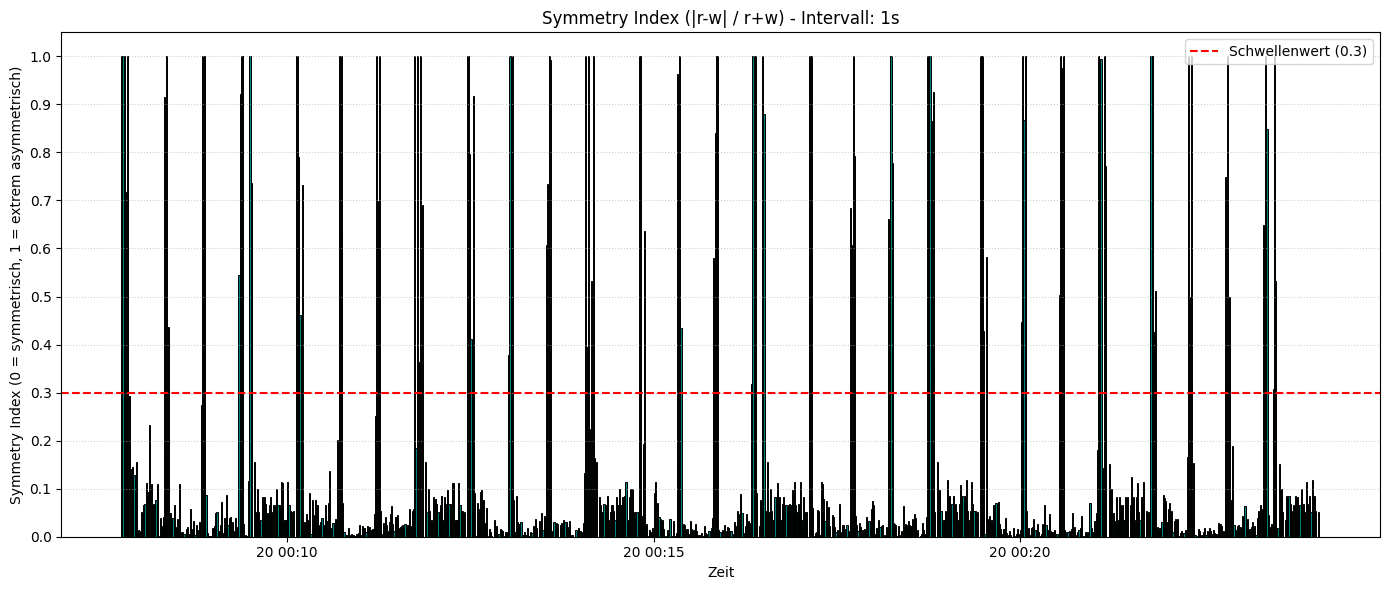


--- Analyse für Intervall: 2s ---


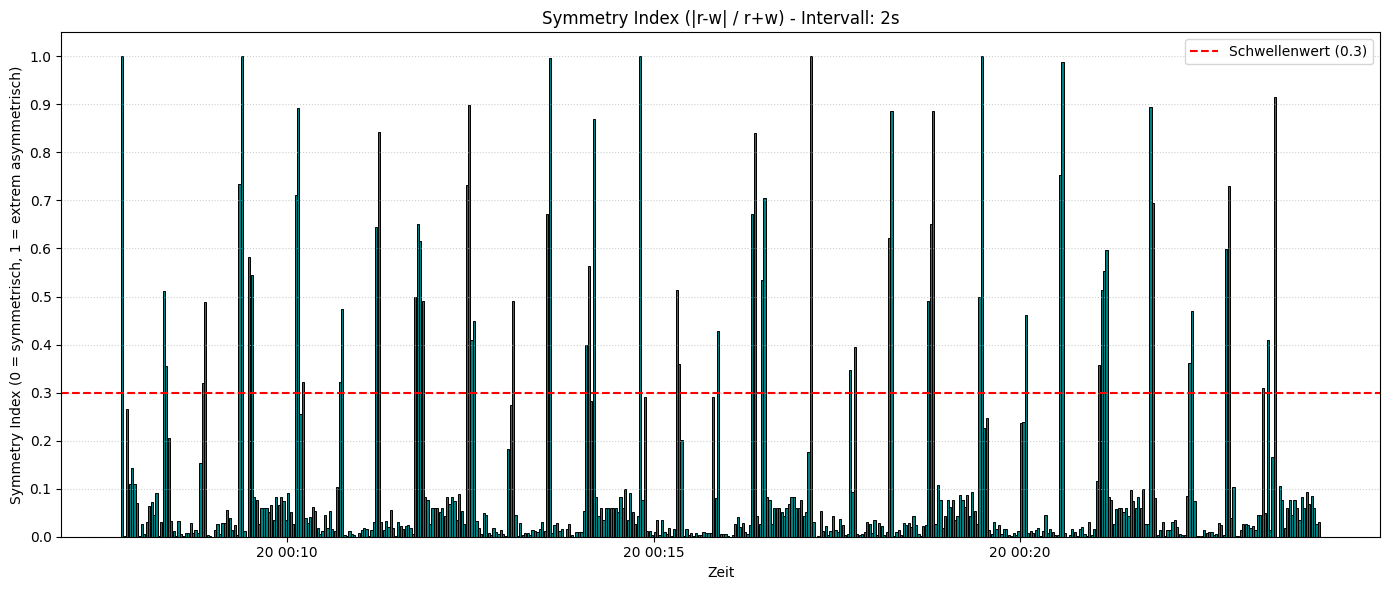


--- Analyse für Intervall: 4s ---


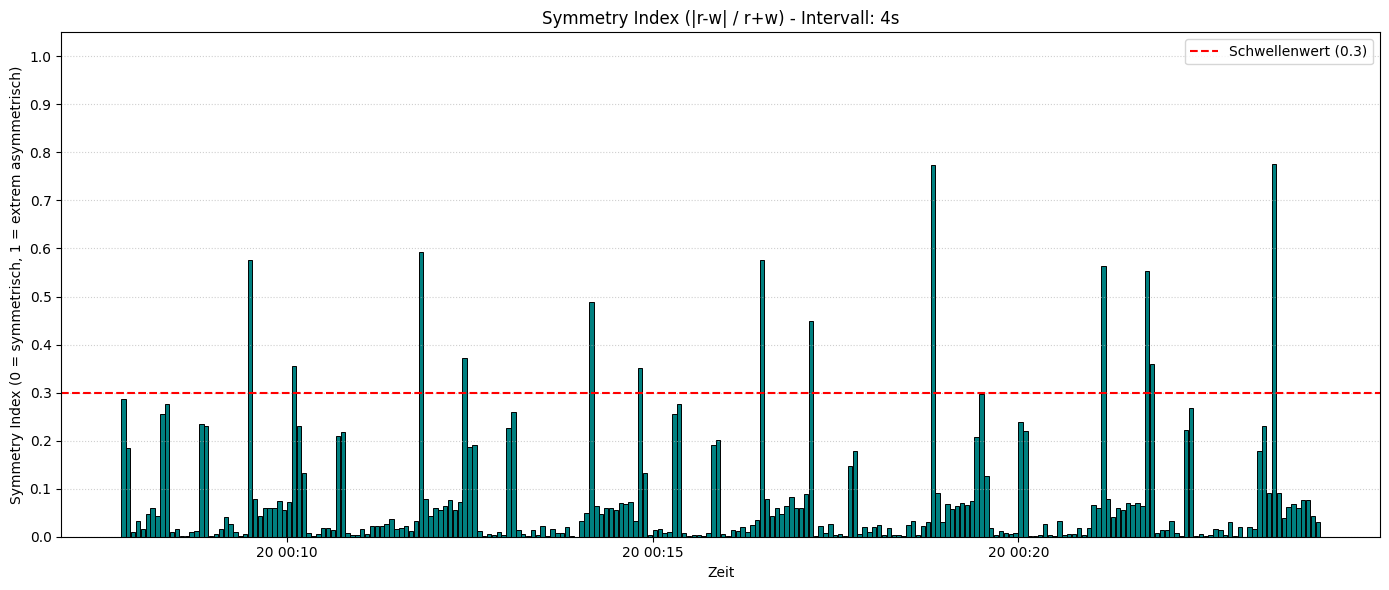

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Daten vorbereiten (falls df noch nicht existiert oder index kein Datetime ist)
if 'timestamp' in df.columns:
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df = df.set_index('timestamp')

# Hilfsspalten sicherstellen
if 'read_count' not in df.columns:
    df['read_count'] = df['op'].astype(str).str.contains('read', case=False, na=False).astype(int)
if 'write_count' not in df.columns:
    df['write_count'] = df['op'].astype(str).str.contains('write', case=False, na=False).astype(int)

# Deine gewünschten Intervalle
interval_sizes = ['250ms', '500ms', '1s', '2s', '4s']

for interval in interval_sizes:
    print(f"\n--- Analyse für Intervall: {interval} ---")

    # Aggregation
    resampled_df = df.resample(interval)[['read_count', 'write_count']].sum()

    # Symmetrie-Index berechnen: |r - w| / (r + w)
    r = resampled_df['read_count']
    w = resampled_df['write_count']
    
    # Berechnung durchführen. Wenn r+w=0 (kein Traffic), entsteht NaN.
    # Wir füllen diese leeren Intervalle mit 0 auf (oder lassen sie als NaN, je nachdem ob du Balken willst)
    resampled_df['symmetry'] = np.abs(r - w) / (r + w)
    resampled_df['symmetry'] = resampled_df['symmetry'].replace([np.inf, -np.inf], np.nan).fillna(0)

    # Plotting
    plt.figure(figsize=(14, 6))

    # Berechnung der Balkenbreite für Matplotlib
    width_seconds = pd.to_timedelta(interval).total_seconds()
    width_plot = width_seconds / 86400 * 0.9

    plt.bar(resampled_df.index, resampled_df['symmetry'],
            width=width_plot,
            align='edge',
            color='teal',
            edgecolor='black',
            linewidth=0.7)

    # Y-Achse auf 0 bis 1 begrenzen (da der Index maximal 1.0 werden kann)
    plt.ylim(0, 1.05)

    # Ticks in 0.1 Schritten
    plt.yticks(np.arange(0, 1.1, 0.1))

    # --- Rote Linie bei 0.3 als Toleranzgrenze ---
    plt.axhline(y=0.3, color='red', linestyle='--', linewidth=1.5, label='Schwellenwert (0.3)')

    plt.title(f'Symmetry Index (|r-w| / r+w) - Intervall: {interval}')
    plt.xlabel('Zeit')
    plt.ylabel('Symmetry Index (0 = symmetrisch, 1 = extrem asymmetrisch)')
    plt.legend()

    # Gitterlinien für jede 0.1 Stufe
    plt.grid(axis='y', linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()


--- Analyse für Intervall: 250ms (Zoom 0-2) ---


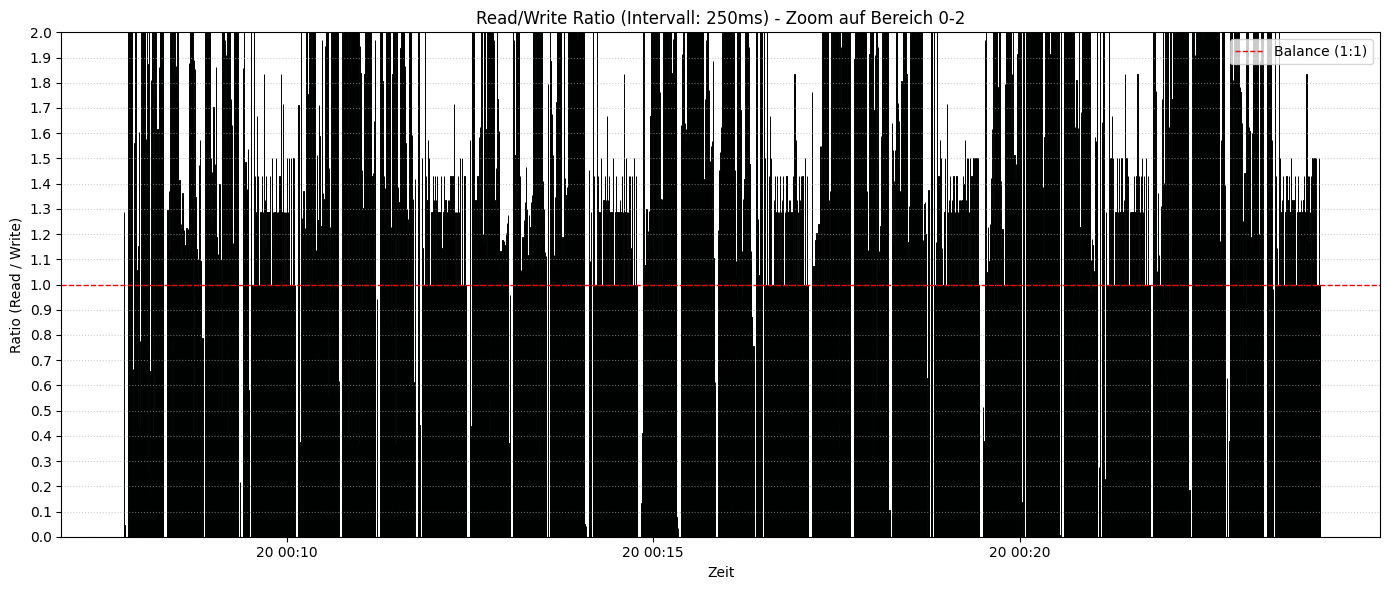


--- Analyse für Intervall: 500ms (Zoom 0-2) ---


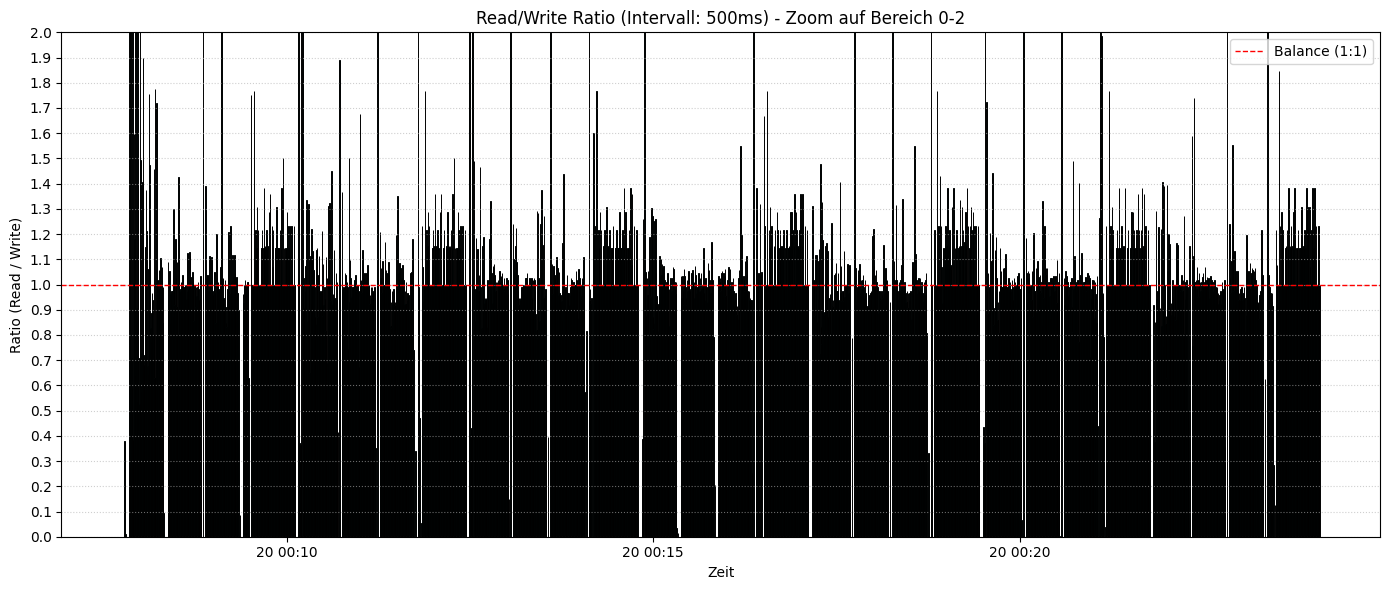


--- Analyse für Intervall: 1s (Zoom 0-2) ---


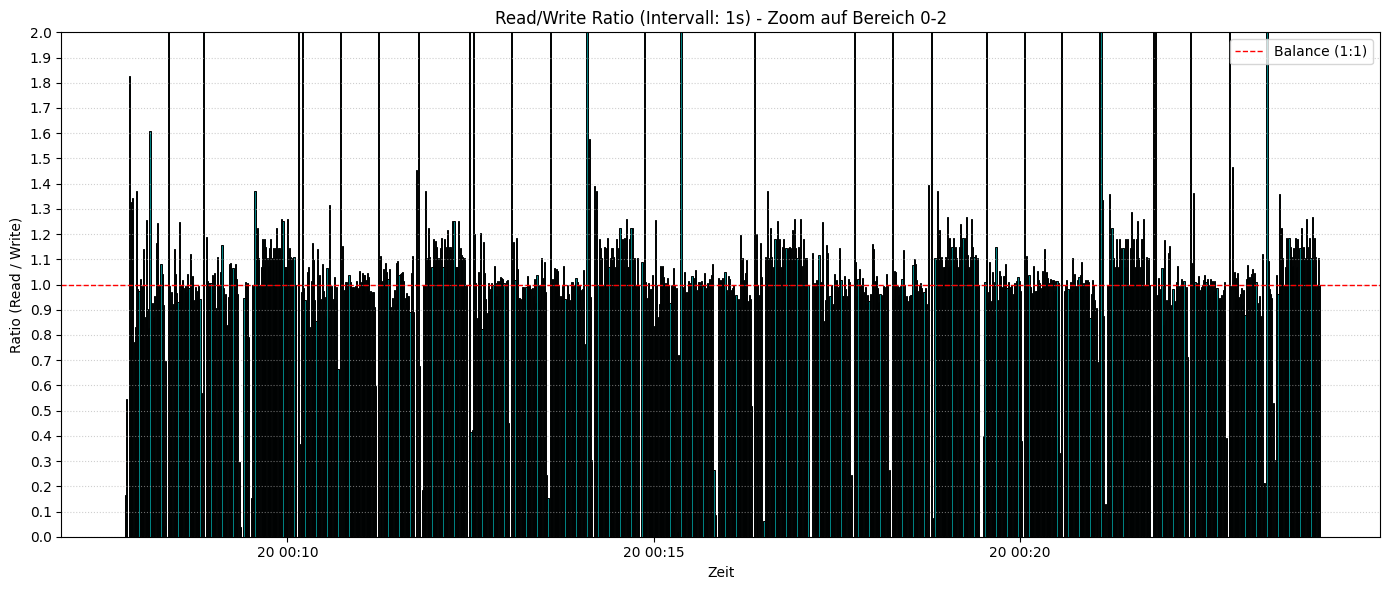


--- Analyse für Intervall: 2s (Zoom 0-2) ---


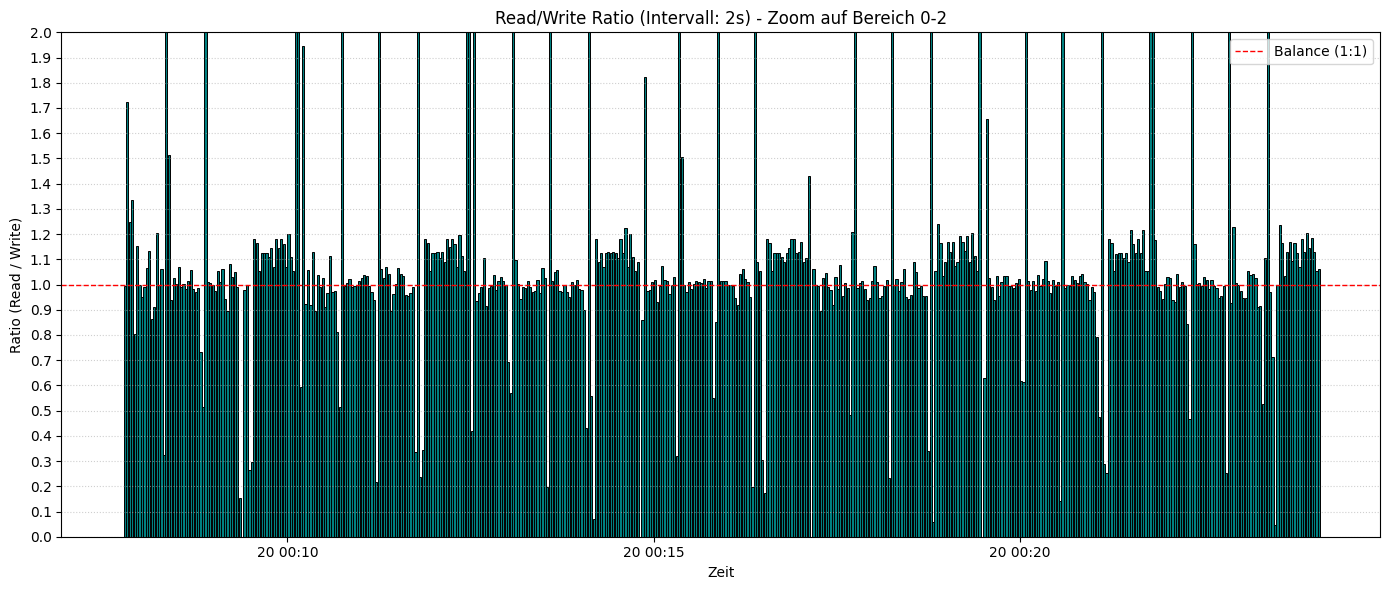


--- Analyse für Intervall: 4s (Zoom 0-2) ---


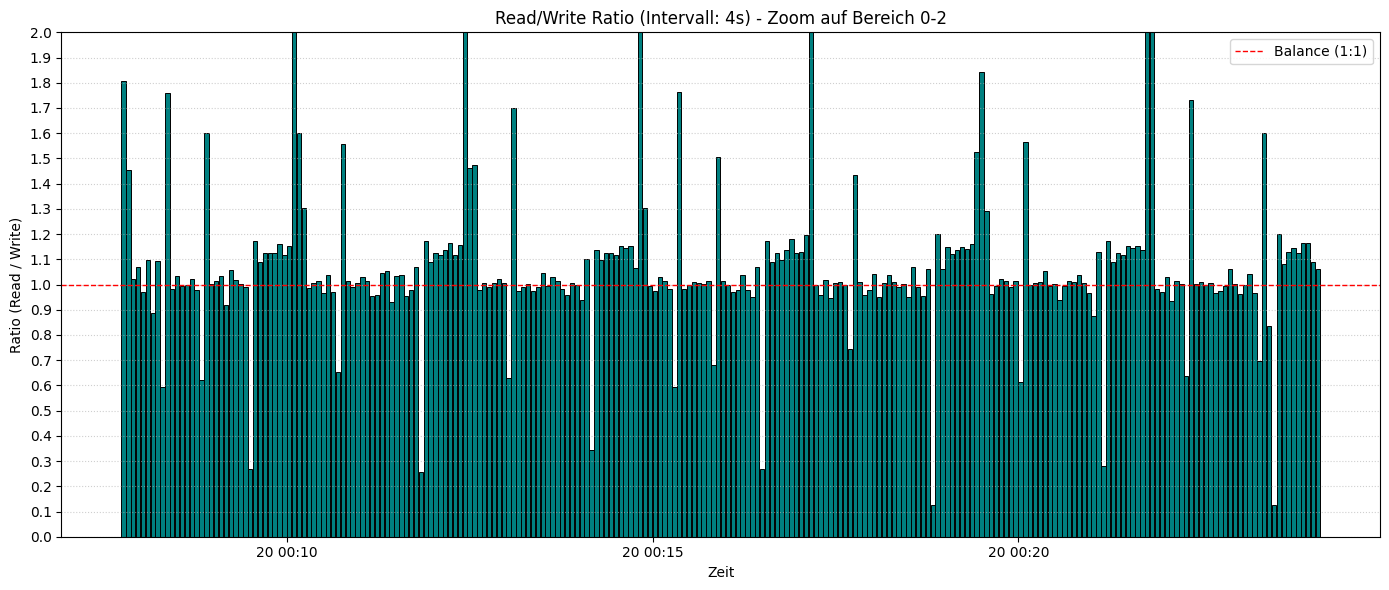

In [17]:


# 1. Daten vorbereiten (falls df noch nicht existiert oder index kein Datetime ist)
if 'timestamp' in df.columns:
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df = df.set_index('timestamp')

# Hilfsspalten sicherstellen
df['read_count'] = df['op'].astype(str).str.contains('read', case=False, na=False).astype(int)
df['write_count'] = df['op'].astype(str).str.contains('write', case=False, na=False).astype(int)

# Deine gewünschten Intervalle
interval_sizes = ['250ms', '500ms', '1s', '2s', '4s']

for interval in interval_sizes:
    print(f"\n--- Analyse für Intervall: {interval} (Zoom 0-2) ---")

    # Aggregation
    resampled_df = df.resample(interval)[['read_count', 'write_count']].sum()

    # Ratio berechnen
    # Wir füllen NaN mit 0 (wenn keine Daten da sind)
    # Inf (durch 0 teilen) ersetzen wir auch, z.B. durch 0 oder einen hohen Wert
    resampled_df['ratio'] = resampled_df['read_count'] / resampled_df['write_count']
    resampled_df['ratio'] = resampled_df['ratio'].replace([np.inf, -np.inf], 0).fillna(0)

    # Plotting
    plt.figure(figsize=(14, 6))

    # Berechnung der Balkenbreite (damit sie sauber aussehen)
    width_seconds = pd.to_timedelta(interval).total_seconds()
    # Umrechnung für Matplotlib Date-Axis (Tag = 1.0, also Sekunden / 86400)
    width_plot = width_seconds / 86400 * 0.9

    plt.bar(resampled_df.index, resampled_df['ratio'],
            width=width_plot,
            align='edge',
            color='teal',
            edgecolor='black',
            linewidth=0.7)

    # --- HIER SIND DIE ÄNDERUNGEN FÜR DEN ZOOM ---

    # 1. Y-Achse hart auf 0 bis 2 begrenzen
    plt.ylim(0, 2)

    # 2. Ticks in 0,1 Schritten setzen (von 0.0 bis 2.0)
    plt.yticks(np.arange(0, 2.1, 0.1))

    # Rote Linie bei 1.0 (Balance) zur Orientierung
    plt.axhline(y=1.0, color='red', linestyle='--', linewidth=1, label='Balance (1:1)')

    # ---------------------------------------------

    plt.title(f'Read/Write Ratio (Intervall: {interval}) - Zoom auf Bereich 0-2')
    plt.xlabel('Zeit')
    plt.ylabel('Ratio (Read / Write)')
    plt.legend()

    # Gitterlinien für jede 0.1 Stufe
    plt.grid(axis='y', linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

Lade Datensätze...
Starte Multi-Szenario Analyse mit Symmetry Index d = |r-w|/(r+w) ...

ANALYSE ABGESCHLOSSEN
Bestes Intervall: 8000ms
→ größter Sicherheitsabstand zwischen Ransomware und dem ähnlichsten Normal-Szenario.

Ergebnisse:
Intervall  MSE_Ransom  Robust_Score  Score_Benign_fileserver_log  Score_Benign_varmail_log  Score_Benign_webserver_log
    250ms    0.210155      4.567477                     4.567477                  4.750255                    4.758404
    500ms    0.103367      9.281873                     9.281873                  9.654566                    9.674247
    750ms    0.104068      9.218889                     9.218889                  9.586585                    9.609088
   1000ms    0.090628     10.579986                    10.579986                 11.011142                   11.034096
   1250ms    0.081417     11.774705                    11.774705                 12.249974                   12.282373
   1500ms    0.073978     12.967704                

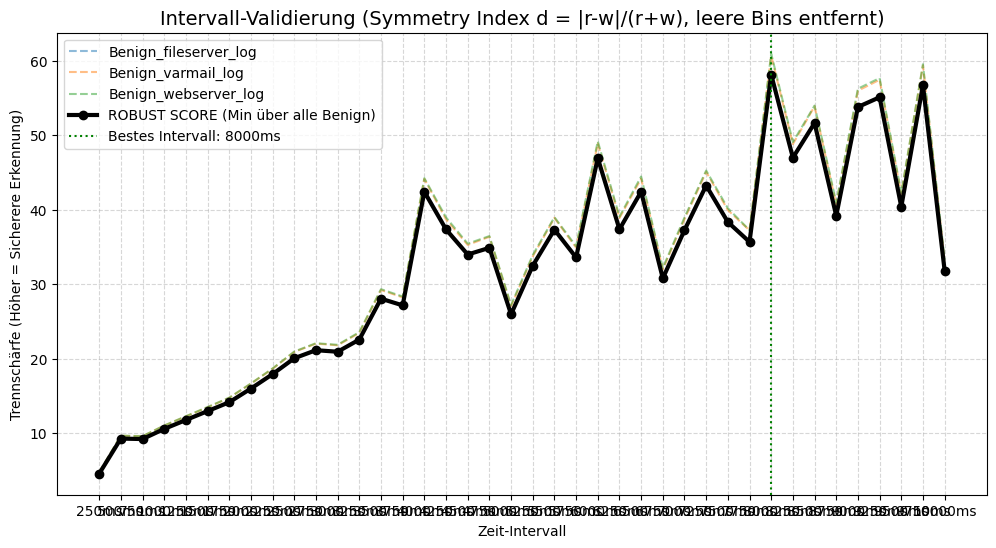

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1) SETUP: HIER NUR PFAD(E) EINTRAGEN
# ==============================================================================

# Ransomware-Datei (ein Pfad)
PATH_RANSOM = '../logs/ransomware_log.csv'

# Normale Dateien (Liste, beliebig viele)
BENIGN_PATHS = [
    '../logs/fileserver_log.csv',
    '../logs/varmail_log.csv',
    '../logs/webserver_log.csv'
] 

    


# Spaltennamen in deinen CSVs
TIME_COL = "timestamp"
OP_COL = "op"

# Intervalle, die wir testen
# Intervalle von 250ms bis 10000ms in 250ms-Schritten
INTERVALS_TO_TEST = [
    "250ms", "500ms", "750ms", "1000ms", "1250ms", "1500ms", "1750ms", "2000ms", 
    "2250ms", "2500ms", "2750ms", "3000ms", "3250ms", "3500ms", "3750ms", "4000ms",
    "4250ms", "4500ms", "4750ms", "5000ms", "5250ms", "5500ms", "5750ms", "6000ms",
    "6250ms", "6500ms", "6750ms", "7000ms", "7250ms", "7500ms", "7750ms", "8000ms",
    "8250ms", "8500ms", "8750ms", "9000ms", "9250ms", "9500ms", "9750ms", "10000ms"
]

# Stabilität nur für den Score-Quotienten (falls mse_r = 0)
EPS_SCORE = 1e-12


# ==============================================================================
# 2) FUNKTIONEN
# ==============================================================================

def load_and_prepare(path: str, label: str) -> pd.DataFrame | None:
    """Lädt Daten, setzt Zeitindex, zählt Reads/Writes pro Event."""
    try:
        df = pd.read_csv(path)

        if TIME_COL not in df.columns or OP_COL not in df.columns:
            raise ValueError(
                f"CSV braucht Spalten '{TIME_COL}' und '{OP_COL}'. "
                f"Gefunden: {list(df.columns)}"
            )

        df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="raise")
        df = df.sort_values(TIME_COL).set_index(TIME_COL)

        op = df[OP_COL].astype(str)
        df["reads"]  = op.str.contains("read",  case=False, na=False).astype(int)
        df["writes"] = op.str.contains("write", case=False, na=False).astype(int)

        df["type"] = label
        return df

    except Exception as e:
        print(f"Fehler beim Laden von {label} ({path}): {e}")
        return None


def calculate_target_mse_symmetry_index(df: pd.DataFrame, interval: str):
    resampled = df.resample(interval)[["reads", "writes"]].sum()
    activity = resampled["reads"] + resampled["writes"]
    resampled = resampled[activity > 0].copy()
    
    if resampled.empty:
        return np.nan, pd.Series(dtype=float)

    r = resampled["reads"].astype(float)
    w = resampled["writes"].astype(float)

    # NEU: Symmetrie-Maß (1 = perfekt 1:1, 0 = rein Read oder rein Write)
    # Wir wollen wissen, wie NAHE die Ransomware an der 1:1 Symmetrie ist.
    s = 1.0 - ((r - w).abs() / (r + w))

    # Wir messen den MSE gegen das Ziel "Symmetrie" (Wert 1.0)
    # Je kleiner der MSE, desto symmetrischer ist der Datensatz insgesamt.
    mse_gegen_symmetrie = ((s - 1.0)**2).mean() 
    
    return float(mse_gegen_symmetrie), s


def short_name(p: str) -> str:
    return Path(p).stem


# ==============================================================================
# 3) DATEN LADEN
# ==============================================================================

print("Lade Datensätze...")

ransom_df = load_and_prepare(PATH_RANSOM, "Ransomware")
if ransom_df is None:
    print("!!! Abbruch: Ransomware-Datensatz konnte nicht geladen werden.")
    sys.exit(1)

if len(BENIGN_PATHS) == 0:
    print("!!! Abbruch: BENIGN_PATHS ist leer.")
    sys.exit(1)

benign_dfs = []
benign_labels = []
for p in BENIGN_PATHS:
    label = f"Benign_{short_name(p)}"
    df = load_and_prepare(p, label)
    if df is None:
        print("!!! Abbruch: Mindestens ein Benign-Datensatz konnte nicht geladen werden.")
        sys.exit(1)
    benign_dfs.append(df)
    benign_labels.append(label)

# ==============================================================================
# 4) ANALYSE
# ==============================================================================

results = []

print("Starte Multi-Szenario Analyse mit Symmetry Index d = |r-w|/(r+w) ...")
for interval in INTERVALS_TO_TEST:
    mse_r, _ = calculate_target_mse_symmetry_index(ransom_df, interval)

    benign_scores = []
    for df in benign_dfs:
        mse_b, _ = calculate_target_mse_symmetry_index(df, interval)

        if np.isnan(mse_r) or np.isnan(mse_b):
            score = np.nan
        else:
            # Score-Quotient; EPS nur als Schutz wenn mse_r wirklich 0 wird
            score = mse_b / (mse_r + EPS_SCORE)

        benign_scores.append(score)

    # Robust: Minimum über alle Benign-Szenarien (NaNs ignorieren)
    robust_score = np.nanmin(benign_scores) if not all(np.isnan(s) for s in benign_scores) else np.nan

    row = {
        "Intervall": interval,
        "MSE_Ransom": mse_r,
        "Robust_Score": robust_score,
    }
    for label, score in zip(benign_labels, benign_scores):
        row[f"Score_{label}"] = score

    results.append(row)

res_df = pd.DataFrame(results)

best_interval = None
if res_df["Robust_Score"].notna().any():
    best_interval = res_df.loc[res_df["Robust_Score"].idxmax(), "Intervall"]

print("\nANALYSE ABGESCHLOSSEN")
if best_interval is None:
    print("Konnte kein bestes Intervall bestimmen (zu viele NaNs / keine aktiven Bins?).")
else:
    print(f"Bestes Intervall: {best_interval}")
    print("→ größter Sicherheitsabstand zwischen Ransomware und dem ähnlichsten Normal-Szenario.")

print("\nErgebnisse:")
print(res_df.to_string(index=False))

# ==============================================================================
# 5) PLOTTING
# ==============================================================================

plt.figure(figsize=(12, 6))

for label in benign_labels:
    col = f"Score_{label}"
    plt.plot(res_df["Intervall"], res_df[col], "--", alpha=0.5, label=label)

plt.plot(
    res_df["Intervall"],
    res_df["Robust_Score"],
    marker="o",
    color="black",
    linewidth=3,
    label="ROBUST SCORE (Min über alle Benign)"
)

if best_interval is not None:
    plt.axvline(best_interval, color="green", linestyle=":", label=f"Bestes Intervall: {best_interval}")

plt.title("Intervall-Validierung (Symmetry Index d = |r-w|/(r+w), leere Bins entfernt)", fontsize=14)
plt.ylabel("Trennschärfe (Höher = Sicherere Erkennung)")
plt.xlabel("Zeit-Intervall")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()
